# Simple Water Balance Model (SWBM)

Notebook version of [`swbm.py`](swbm.py). Run the cells from top to bottom (*Runtime → Run all* in Colab).

## Section 1: Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Section 2: Define Functions

In [2]:
def prepro(raw_data):
    """ Preprocess data for SWBM
    Convert runoff, latent heat flux and surface net radiation to mm.
    Convert time to date.

    :param raw_data: raw input data (pandas df):
         -snr: surface net radiation
         -tp: total precipitation
         -ro: runoff
         -sm: soil moisture at the surface
         -le: latent heat flux
    :return: pre-processed data (pandas df)
    """

    # Target unit is mm/day (1 mm of water on 1 m2 = 1 kg = 1 L).
    #
    # Model drivers (tp, snr) MUST be in mm/day: they are added to and
    # compared with soil moisture and c_s (both in mm).
    #
    # Observations (sm, ro, le) are only used in model_correlation. Pearson
    # correlation ignores multiplying by a constant, so for the correlation
    # these conversions change nothing. They put the observations on the
    # same scale as the model output, e.g. for plotting or comparing amounts.
    #
    # tp  [mm/day]   -> already in mm, no conversion.
    # snr [MJ/m2/day] -> / 2.26: as in the lecture, the factor lambda * rho_w
    #                   from the ET function (latent heat of vaporization
    #                   times water density) is approximated by 2.26. This
    #                   gives the depth of water the energy could evaporate.
    # sm  [m3/m3]    -> * 1000 mm: water depth in a 1 m deep soil column.
    #                   The observed layer is shallower than 1 m, so this is
    #                   a rescaling to the size of the modelled soil moisture,
    #                   not the true water content.
    # ro  [m/hour, daily mean] -> * 24 h * 1000 mm/m = mm/day.
    # le  [W/m2 = J/s/m2]      -> * 86400 s/day / 2,260,000 J/kg = kg/m2/day = mm/day
    #                             (same 2.26 approximation as for snr).
    data = {'time': pd.to_datetime(raw_data['time']),
            'lat': raw_data['latitude'],
            'long': raw_data['longitude'],
            'tp': raw_data['tp_[mm]'],
            'sm': raw_data['sm_[m3/m3]'] * 1000,
            'ro': raw_data['ro_[m]'] * 24000,
            'le': raw_data['le_[W/m2]'] * (86400 / 2260000),
            'snr': raw_data['snr_[MJ/m2]'] * (1 / 2.26),
            }
    return pd.DataFrame(data)

In [3]:
def et_fraction(b0, w_i, c_s, g):
    """Compute proportion of maximum ET that occurs given current soil moisture."""
    w_i = np.minimum(w_i, c_s)
    # soil moisture cannot exceed water holding capacity
    return b0 * (w_i / c_s+0.0000000001) ** g

In [4]:
def runoff_fraction(w_i, c_s, a):
    """Compute runoff fraction."""
    return np.minimum((w_i / c_s) ** a, 1)

In [5]:
def predict_sm(curr_moist, evapo, wrunoff, precip, rad):
    """Update soil moisture for next step."""
    return curr_moist + (precip - (evapo * rad) - (wrunoff * precip))

In [6]:
def predict_ts(data, config, n_days=None):
    """Run the SWBM for given time series

    :param data: input data (pandas df) (time, tp, sm, ro, le, snr)
    :param config: parameters
                   - water holding capacity (c_s),
                   - maximum of ET function (b0),
                   - ET function shape (g),
                   - runoff function shape (a))
    :param n_days: time series length (default: None)
    :return: soil moisture, runoff, ET (for entire ts) (numpy arrays)
    """
    n_days = data.shape[0] if n_days is None else n_days

    # Initialize arrays for model outputs
    moists, runoff_fracs, et_fracs, time = np.zeros(n_days), np.zeros(n_days), np.zeros(n_days), np.zeros(n_days)
    
    # Initial soil moisture (90% of soil water holding capacity)
    moists[0] = 0.9 * config['c_s']
    
    # Parameters
    c_s = config['c_s']
    b0 = config['b0']
    g = config['g']
    a = config['a']

    eps = 1e-10

    for i in range(n_days):
        # Compute evapotranspiration fraction
        if moists[i] <= 0:
            moists[i] = eps
        # what fraction of the available energy can actually drive evaporation right now?
        et_fracs[i] = et_fraction(b0, moists[i], c_s, g)
        if moists[i] == 0:
            et_fracs[i] = 0

        # Compute runoff fraction
        # what fraction of incoming rainfall will run off rather than soak in?
        runoff_fracs[i] = runoff_fraction(moists[i], c_s, a)

        # Compute soil moisture for the next timestep
        if i < n_days - 1: # Avoid updating beyond the last index
            moists[i + 1] = predict_sm(moists[i], et_fracs[i], runoff_fracs[i],
                                    data['tp'][i], data['snr'][i])


    # Convert runoff and ET fractions to actual fluxes
    runoffs = runoff_fracs * np.asarray(data['tp'])[:n_days] # fraction × precipitation
    ets = et_fracs * np.asarray(data['snr'])[:n_days] # fraction × net radiation

    #add time
    time = data['time']

    return moists, runoffs, ets, time

In [7]:
def model_correlation(data, model_outputs, start=None, end=None):
    """
    Calculate correlation between observed data and model outputs,
    optionally restricted to a timeframe.

    :param data: pandas DataFrame with columns 'sm', 'ro', 'le' (observed)
    :param model_outputs: tuple of numpy arrays (moists, runoffs, ets)
    :param start: str or datetime, start date for analysis (optional)
    :param end: str or datetime, end date for analysis (optional)
    :return: dict with individual correlations and sum of correlations
    """
    moists, runoffs, ets = model_outputs

    # Apply timeframe selection if provided
    if start is not None or end is not None:
        mask = (data['time'] >= pd.to_datetime(start) if start else True) & \
               (data['time'] <= pd.to_datetime(end) if end else True)
        data = data.loc[mask]
        moists = moists[data.index]
        runoffs = runoffs[data.index]
        ets = ets[data.index]

    # Compute correlations
    corr_sm = np.corrcoef(data['sm'], moists)[0, 1]
    corr_ro = np.corrcoef(data['ro'], runoffs)[0, 1]
    corr_et = np.corrcoef(data['le'], ets)[0, 1]

    corr_sum = corr_sm + corr_ro + corr_et

    return {'sm': corr_sm, 'ro': corr_ro, 'et': corr_et, 'sum': corr_sum}

## Section 3: Main Execution

In [8]:
# Load data from GitHub (offline: set DATA_URL to your local data folder, e.g. 'data/')
#DATA_URL = 'https://raw.githubusercontent.com/Motzemoere/Earth-System-Modelling/main/data/'
data_germany = pd.read_csv('data/Data_swbm_Germany.csv')
data_sweden = pd.read_csv('data/Data_swbm_Sweden.csv')
data_spain = pd.read_csv('data/Data_swbm_Spain.csv')
# Prepare the data
data_germany_prepro = prepro(data_germany)
data_spain_prepro = prepro(data_spain)
data_sweden_prepro = prepro(data_sweden)

datasets = [data_germany_prepro,data_spain_prepro,data_sweden_prepro]

In [9]:
# Run the SWBM model
# moisture, runoff, et_flux = predict_ts(data, config)

In [10]:
# Compute correlation over the whole timeseries
# corrs = model_correlation(data_germany_prepro, (moisture, runoff, et_flux))
# print("Correlation between observed data and model outputs:\n")
# print(f"Soil Moisture (sm):    {corrs['sm']:.3f}")
# print(f"Runoff (ro):           {corrs['ro']:.3f}")
# print(f"Evapotranspiration (et): {corrs['et']:.3f}")
# print(f"\nSum of correlations:   {corrs['sum']:.3f}")

## Section 5: Variation of parameters

#### Variation of water capacity:

##### Configurating the variations:

In [11]:
# Define initial parameters with no water capacity
config_low = {
    'name': "No water capacity",
    'c_s' : 10 ,    # soil water holding capacity in mm
    'a': 4,        # runoff function shape α
    'g': 0.5,      # ET function shape γ
    'b0': 0.8      # maximum of ET function β
}
# Define initial parameters with med water capacity
config_med = {
    'name': "Medium water capacity",
    'c_s': 210,    # soil water holding capacity in mm
    'a': 4,        # runoff function shape α
    'g': 0.5,      # ET function shape γ
    'b0': 0.8      # maximum of ET function β
}

# Define initial parameters with normal water capacity
config_norm = {
    'name': "Normal water capacity",
    'c_s': 420,    # soil water holding capacity in mm
    'a': 4,        # runoff function shape α
    'g': 0.5,      # ET function shape γ
    'b0': 0.8      # maximum of ET function β
}
# Define initial parameters with high water capacity
config_high = {
    'name': "High water capacity",
    'c_s': 600,    # soil water holding capacity in mm
    'a': 4,        # runoff function shape α
    'g': 0.5,      # ET function shape γ
    'b0': 0.8      # maximum of ET function β
}
configs = [config_low, config_med, config_norm, config_high]

##### Calculating Results

In [12]:
def get_results(data_prepro, config):
    moisture, runoff, et_flux, time = predict_ts(data_prepro, config)

    if data_prepro is data_germany_prepro:
        country = "Germany"
    elif data_prepro is data_sweden_prepro:
        country = "Sweden"
    elif data_prepro is data_spain_prepro:
        country = "Spain"

    dict_results = {
            'country' : country,
            'time' : time,
            'moisture' : moisture,
            'runoff' : runoff,
            'et_flux' : et_flux
        }
    return dict_results



res_ls = []
for data_prepro in datasets:
    for config in configs:
        this_result = get_results(data_prepro, config)
        row_ls = []
        for i in range(len(this_result['moisture'])):
                row_dict = {
                    'country': this_result['country'],
                    'config' : config['name'],
                    'time': this_result['time'][i],
                    'soil_moisture': this_result['moisture'][i],
                    'runoff': this_result['runoff'][i],
                    'et_flux': this_result['et_flux'][i]
                }
                row_ls.append(row_dict)
                # print(row_dict)
        for entry in row_ls:
            res_ls.append(entry)


df_results = pd.DataFrame(res_ls)
df_results

,country,config,time,soil_moisture,runoff,et_flux
0,Germany,No water capacity,2008-01-01,9.000000,0.005416,-0.359180
1,Germany,No water capacity,2008-01-02,9.362019,0.001921,-0.740924
2,Germany,No water capacity,2008-01-03,10.103522,0.013233,-0.221388
3,Germany,No water capacity,2008-01-04,10.324910,0.000887,-0.294015
4,Germany,No water capacity,2008-01-05,10.618925,12.935702,-0.029899
...,...,...,...,...,...,...
48211,Sweden,High water capacity,2018-12-27,529.243306,0.263249,-0.861660
48212,Sweden,High water capacity,2018-12-28,530.276578,0.018687,-1.359571
48213,Sweden,High water capacity,2018-12-29,531.648091,0.349884,-1.960452
48214,Sweden,High water capacity,2018-12-30,533.826246,0.001573,-1.964767


#### Plotting

In [13]:
# sns relplot here ???
import seaborn as sns
res_ger = df_results[df_results["country"] == "Germany"]
res_spa = df_results[df_results["country"] == "Spain"]
res_swe = df_results[df_results["country"] == "Sweden"]

In [14]:
# sns.relplot(data = df_results, x= "time", y = "runoff", kind = "line", hue = "config", row = "country", col = )

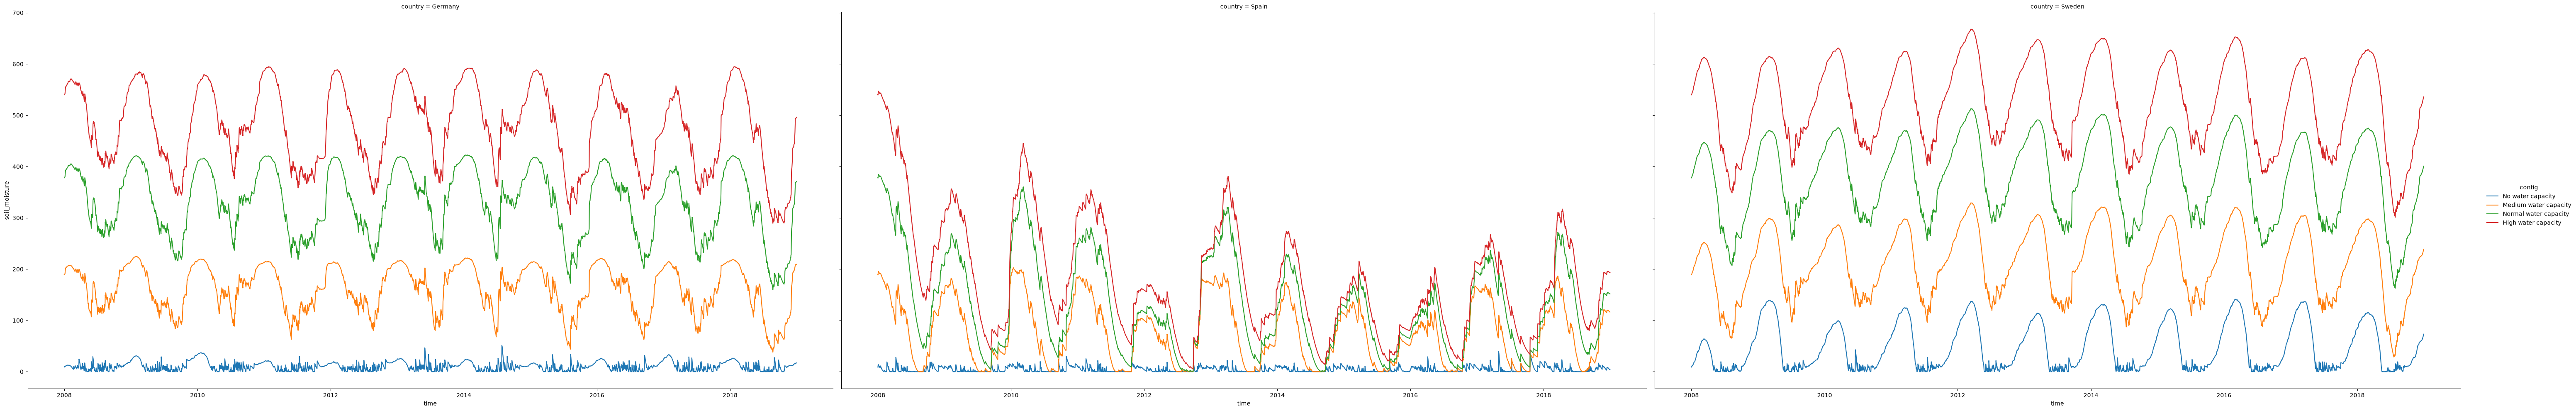

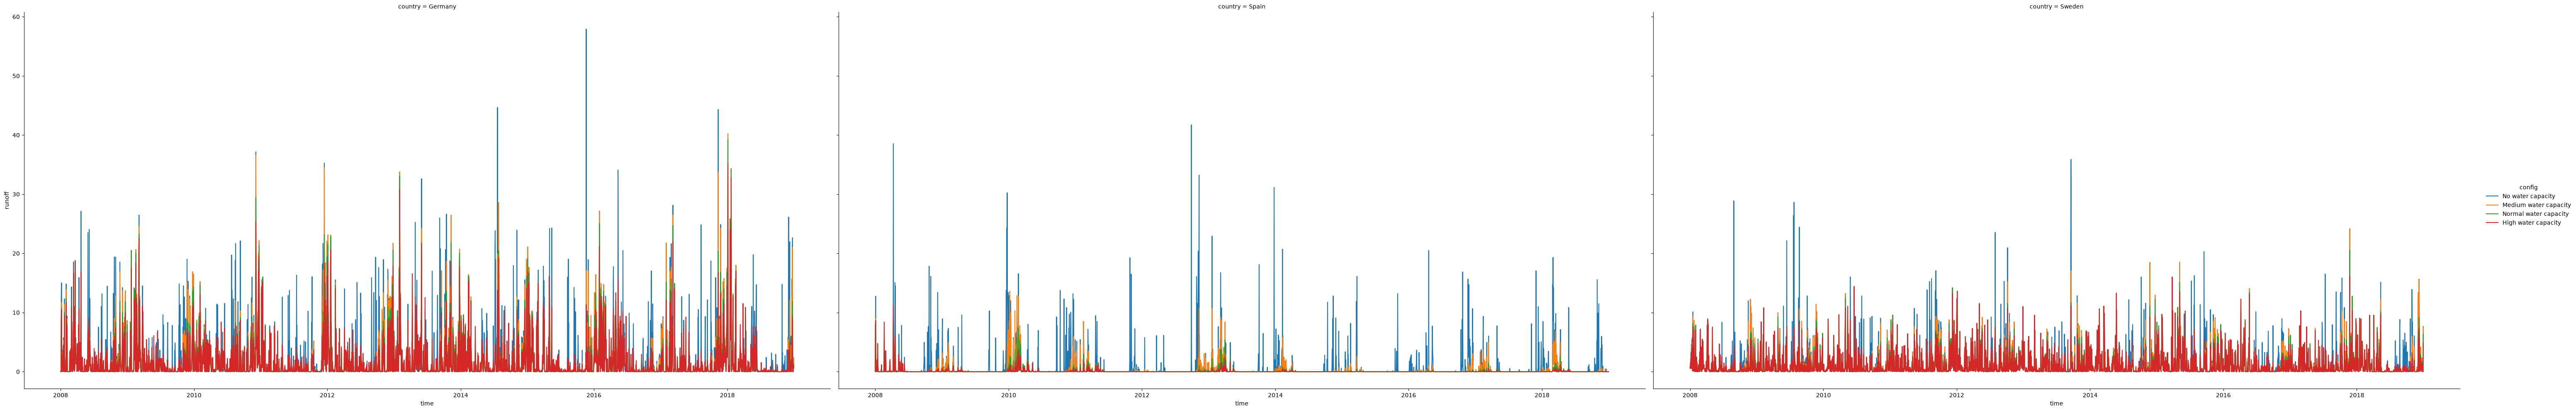

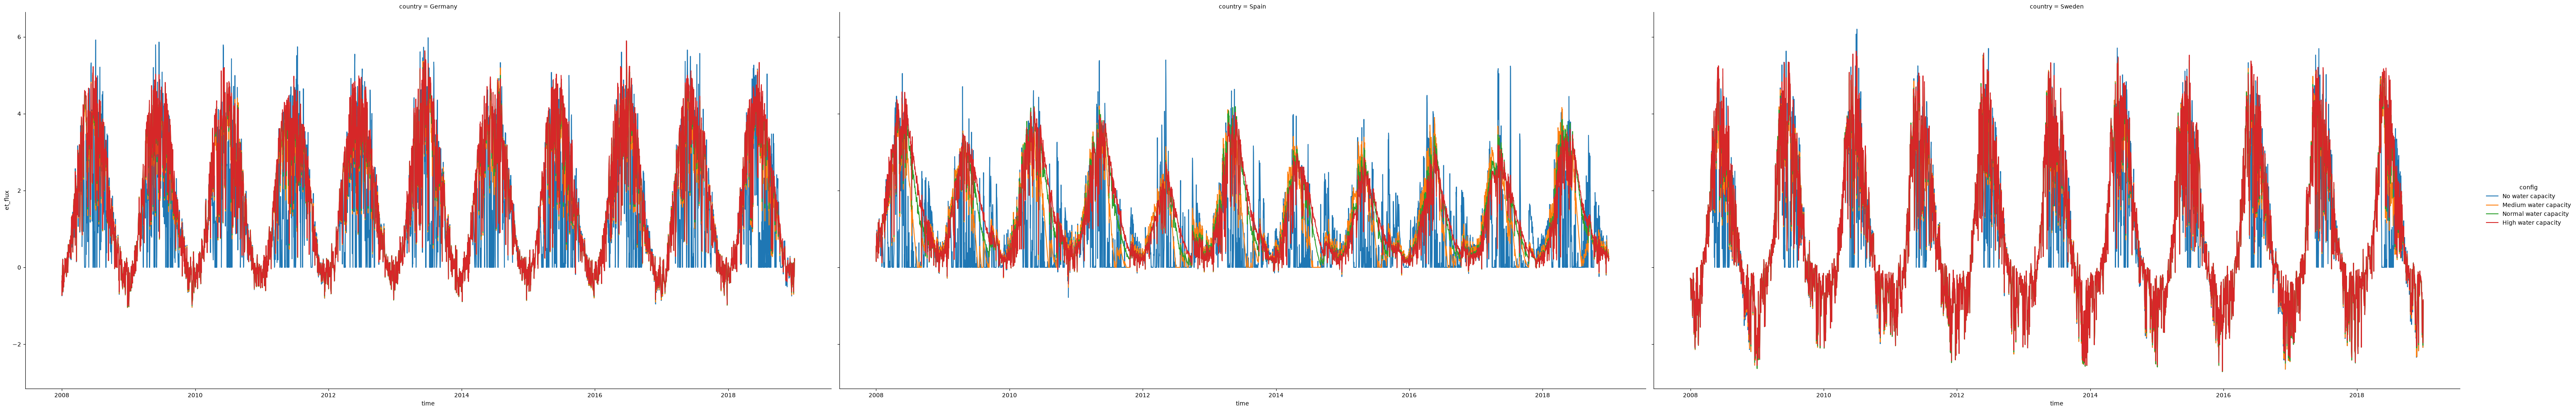

In [18]:
sns.relplot(
    data=df_results,
    x="time",
    y="soil_moisture",
    kind="line",
    hue="config",
    col="country",  
    height=10,
    aspect=2)
    
sns.relplot(
    data=df_results,
    x="time",
    y="runoff",
    kind="line",
    hue="config",
    col="country",  
    height=10,
    aspect=2)

sns.relplot(
    data=df_results,
    x="time",
    y="et_flux",
    kind="line",
    hue="config",
    col="country",  
    height=10,
    aspect=2);
